# Quem usa o ônibus e quem usa o metrô em São Paulo?
## Classificação do perfil dos usuários de transporte público com regressão logística

**Global Solution 2026.2 · CitizenTech · Modelagem Linear para Aprendizado de Máquina**
Lucas Barreto Santana · RM 573149 · 1CCPG

**Base de dados:** Pesquisa Origem e Destino 2017 da Região Metropolitana de São Paulo, realizada pela Companhia do Metropolitano de São Paulo (Metrô). Microdados reais, coletados em entrevistas domiciliares.

**Serviços públicos analisados:** ônibus municipal de São Paulo (SPTrans), Metrô e trem (CPTM).

**Pergunta:** a partir do perfil de uma pessoa (sexo, faixa etária, escolaridade, faixa de renda, situação de trabalho e posse de carro), é possível classificar qual serviço público de transporte ela usa? Quais características mais pesam?

Este notebook baixa os dados sozinho e reproduz todos os números do relatório. Basta executar tudo em ordem (no Colab: Ambiente de execução, Executar tudo).

## 0. Preparação do ambiente

In [1]:
import hashlib
import os
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy.stats import chi2_contingency
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, accuracy_score,
                             balanced_accuracy_score, classification_report, confusion_matrix,
                             f1_score, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEMENTE = 42   # deixa a divisão treino/teste igual em toda execução
os.makedirs("figuras", exist_ok=True)   # os gráficos também são salvos para o relatório
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

# Microdados da OD 2017 (fonte: Metrô de SP), redistribuídos sem alteração pelo pacote odbr
URL_DADOS = "https://github.com/hsvab/odbr/releases/download/v0.1.0/od_sao_paulo_2017_not_harmonized.csv.gz"
ARQUIVO = "od_sao_paulo_2017_not_harmonized.csv.gz"
SHA256_ESPERADO = "ced7db641acab89efc5e821a87ab2dd08fd42ca14fab2137ef788eb7a17c60bd"

if not os.path.exists(ARQUIVO):
    print("Baixando os microdados (8,4 MB)...")
    urllib.request.urlretrieve(URL_DADOS, ARQUIVO)

with open(ARQUIVO, "rb") as arquivo:
    sha = hashlib.sha256(arquivo.read()).hexdigest()
print("Arquivo íntegro (mesmo usado no relatório):", sha == SHA256_ESPERADO)

Arquivo íntegro (mesmo usado no relatório): True


## 1. Carregamento e entendimento da base

A OD 2017 tem **um registro por viagem**, e cada registro traz também os dados do domicílio e da pessoa. Variáveis usadas (códigos do dicionário oficial da pesquisa):

| Variável | Significado | Códigos |
|---|---|---|
| `muni_dom` | município do domicílio | 36 = São Paulo |
| `id_pess`, `n_viag` | identificação da pessoa e número da viagem | |
| `modoprin` | modo principal da viagem | 1 = metrô, 2 = trem, 4 = ônibus do município de São Paulo |
| `sexo` | sexo | 1 = masculino, 2 = feminino |
| `idade` | idade em anos | |
| `grau_ins` | grau de instrução | 1 = não alfabetizado/fund. I incompleto ... 5 = superior completo |
| `cd_ativi` | condição de atividade | 1 = trabalho regular, 2 = bico, 3 = licença, 4 = aposentado, 5 = sem trabalho, 6 = nunca trabalhou, 7 = dona de casa, 8 = estudante |
| `renda_fa`, `no_moraf` | renda familiar mensal (R$ de 2017) e número de moradores da família | |
| `qt_auto` | automóveis no domicílio | |
| `fe_pess` | fator de expansão (quantas pessoas da população cada entrevistado representa) | |

O `modoprin` segue uma hierarquia da própria pesquisa: se a viagem usa metrô em algum trecho, o modo principal é metrô, mesmo que a pessoa tenha pegado um ônibus até a estação.

In [2]:
od = pd.read_csv(ARQUIVO, sep=";", low_memory=False)
print(f"Registros (viagens + pessoas sem viagem): {len(od):,}")
print(f"Colunas: {od.shape[1]}")
print(f"Pessoas entrevistadas: {od['id_pess'].nunique():,}")
print(f"Pessoas morando no município de São Paulo: {od.loc[od['muni_dom'] == 36, 'id_pess'].nunique():,}")

Registros (viagens + pessoas sem viagem): 183,092
Colunas: 128
Pessoas entrevistadas: 86,318
Pessoas morando no município de São Paulo: 57,496


## 2. Pré-processamento

**Recorte:**

1. Só moradores do **município de São Paulo** (`muni_dom = 36`), onde os três serviços existem e o ônibus municipal é o da SPTrans.
2. Só viagens cujo modo principal é **metrô, trem ou ônibus municipal de São Paulo**. O monotrilho (1 viagem) foi descartado.
3. **Uma linha por pessoa:** o serviço da pessoa é o da sua **primeira viagem de transporte público no dia**. Assim, quem viaja mais vezes não pesa mais no modelo.

**Variáveis de perfil criadas:**

| Variável | Como foi criada |
|---|---|
| Faixa etária | até 17, 18 a 29, 30 a 44, 45 a 59, 60 ou mais |
| Escolaridade | os 5 níveis de `grau_ins`, com nomes curtos |
| Faixa de renda | renda familiar ÷ moradores, em salários mínimos de 2017 (R$ 937): até 1/2, 1/2 a 1, 1 a 2, 2 a 3, mais de 3 |
| Situação | trabalha (códigos 1 a 3), estudante (8), aposentado (4), sem trabalho ou do lar (5 a 7) |
| Carros no domicílio | 0, 1, 2 ou mais |

As 344 pessoas sem a informação de carros no domicílio foram retiradas (2,2% da base).

In [3]:
SERVICOS = {4: "Ônibus municipal", 1: "Metrô", 2: "Trem"}
SALARIO_MINIMO_2017 = 937

viagens = od[(od["muni_dom"] == 36) & (od["modoprin"].isin(SERVICOS))].copy()
viagens = viagens.sort_values(["id_pess", "n_viag"])
pessoas = viagens.groupby("id_pess", as_index=False).first()
print(f"Viagens de transporte público de moradores de SP: {len(viagens):,}")
print(f"Pessoas (uma linha por pessoa): {len(pessoas):,}")

usa_mais_de_um = viagens.groupby("id_pess")["modoprin"].nunique().gt(1).sum()
print(f"Pessoas que usaram mais de um dos serviços no dia: {usa_mais_de_um:,} "
      f"({usa_mais_de_um / len(pessoas):.1%})")

dados = pd.DataFrame({
    "servico": pessoas["modoprin"].map(SERVICOS),
    "sexo": pessoas["sexo"].map({1: "Masculino", 2: "Feminino"}),
    "faixa_etaria": pd.cut(pessoas["idade"], [-1, 17, 29, 44, 59, 200],
                           labels=["até 17", "18 a 29", "30 a 44", "45 a 59", "60 ou mais"]),
    "escolaridade": pessoas["grau_ins"].map({
        1: "1 Fund. I incompleto", 2: "2 Fund. I completo", 3: "3 Fund. II completo",
        4: "4 Médio completo", 5: "5 Superior completo"}),
    "faixa_renda": pd.cut(pessoas["renda_fa"] / pessoas["no_moraf"] / SALARIO_MINIMO_2017,
                          [-0.01, 0.5, 1, 2, 3, np.inf],
                          labels=["até 1/2 SM", "1/2 a 1 SM", "1 a 2 SM", "2 a 3 SM", "mais de 3 SM"]),
    "situacao": pessoas["cd_ativi"].map({
        1: "Trabalha", 2: "Trabalha", 3: "Trabalha", 4: "Aposentado", 8: "Estudante",
        5: "Sem trabalho/do lar", 6: "Sem trabalho/do lar", 7: "Sem trabalho/do lar"}),
    "carros": pd.cut(pessoas["qt_auto"], [-1, 0, 1, 100], labels=["0", "1", "2 ou mais"]),
    "peso": pessoas["fe_pess"],
    # distância em linha reta da casa até o centro da zona 1 (Sé), em km; usada só na seção 6
    "dist_centro_km": np.hypot(pessoas["co_dom_x"] - od.loc[od["zona"] == 1, "co_dom_x"].mean(),
                               pessoas["co_dom_y"] - od.loc[od["zona"] == 1, "co_dom_y"].mean()) / 1000,
})

print()
print("Valores ausentes por coluna:")
print(dados.isna().sum()[lambda s: s > 0])
dados = dados.dropna().reset_index(drop=True)
for coluna in ["faixa_etaria", "faixa_renda", "carros"]:
    dados[coluna] = dados[coluna].astype(str)
print(f"\nBase final: {len(dados):,} pessoas")
dados.head()

Viagens de transporte público de moradores de SP: 31,375
Pessoas (uma linha por pessoa): 15,295
Pessoas que usaram mais de um dos serviços no dia: 1,029 (6.7%)

Valores ausentes por coluna:
carros    344
dtype: int64

Base final: 14,951 pessoas


,servico,sexo,faixa_etaria,escolaridade,faixa_renda,situacao,carros,peso,dist_centro_km
0,Metrô,Feminino,18 a 29,4 Médio completo,1 a 2 SM,Trabalha,0,16.664,0.312
1,Metrô,Masculino,18 a 29,3 Fund. II completo,1/2 a 1 SM,Trabalha,0,19.802,0.389
2,Metrô,Masculino,30 a 44,2 Fund. I completo,1/2 a 1 SM,Sem trabalho/do lar,0,19.532,0.389
3,Metrô,Masculino,30 a 44,4 Médio completo,1 a 2 SM,Trabalha,0,19.532,0.393
4,Ônibus municipal,Feminino,60 ou mais,4 Médio completo,1 a 2 SM,Aposentado,0,19.532,0.393


## 3. Análise exploratória

### 3.1 Quantas pessoas usam cada serviço

In [4]:
resumo = pd.DataFrame({
    "pessoas na amostra": dados["servico"].value_counts(),
    "% da amostra": dados["servico"].value_counts(normalize=True) * 100,
    "população estimada (com fator de expansão)": dados.groupby("servico")["peso"].sum().round(),
})
resumo["% da população"] = resumo["população estimada (com fator de expansão)"] / resumo["população estimada (com fator de expansão)"].sum() * 100
resumo.loc[["Ônibus municipal", "Metrô", "Trem"]]

,pessoas na amostra,% da amostra,população estimada (com fator de expansão),% da população
servico,,,,
Ônibus municipal,8655,57.889,"2,062,086.000",62.013
Metrô,5637,37.703,"1,073,040.000",32.269
Trem,659,4.408,"190,128.000",5.718


### 3.2 Análise bivariada: perfil × serviço

Para cada característica, a proporção de pessoas de cada grupo que usa cada serviço.

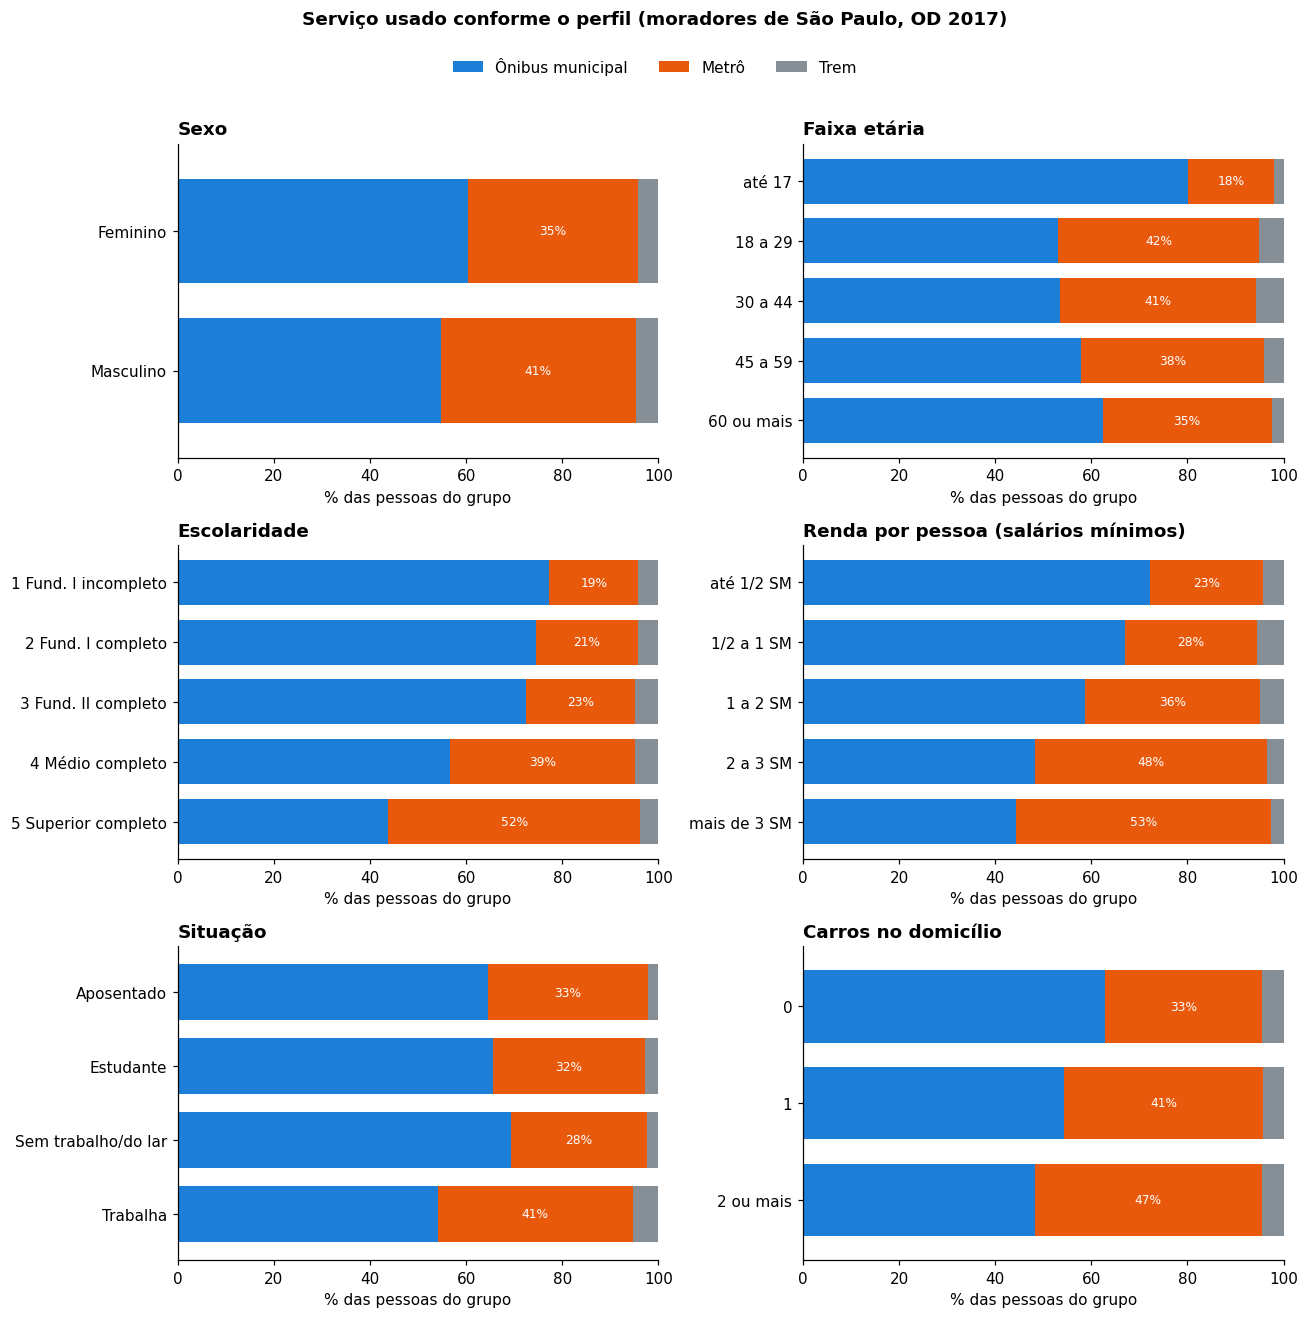

In [5]:
PERFIL = ["sexo", "faixa_etaria", "escolaridade", "faixa_renda", "situacao", "carros"]
NOMES = {"sexo": "Sexo", "faixa_etaria": "Faixa etária", "escolaridade": "Escolaridade",
         "faixa_renda": "Renda por pessoa (salários mínimos)", "situacao": "Situação", "carros": "Carros no domicílio"}
CORES = {"Ônibus municipal": "#1c7ed6", "Metrô": "#e8590c", "Trem": "#868e96"}
ORDEM_SERVICOS = ["Ônibus municipal", "Metrô", "Trem"]
ORDENS = {
    "sexo": ["Feminino", "Masculino"],
    "faixa_etaria": ["até 17", "18 a 29", "30 a 44", "45 a 59", "60 ou mais"],
    "escolaridade": ["1 Fund. I incompleto", "2 Fund. I completo", "3 Fund. II completo",
                     "4 Médio completo", "5 Superior completo"],
    "faixa_renda": ["até 1/2 SM", "1/2 a 1 SM", "1 a 2 SM", "2 a 3 SM", "mais de 3 SM"],
    "situacao": ["Aposentado", "Estudante", "Sem trabalho/do lar", "Trabalha"],
    "carros": ["0", "1", "2 ou mais"],
}

fig, eixos = plt.subplots(3, 2, figsize=(12, 12))
for eixo, variavel in zip(eixos.flat, PERFIL):
    tabela = pd.crosstab(dados[variavel], dados["servico"], normalize="index").loc[ORDENS[variavel], ORDEM_SERVICOS] * 100
    tabela.plot.barh(stacked=True, ax=eixo, color=[CORES[s] for s in ORDEM_SERVICOS], legend=False, width=0.75)
    eixo.set_title(NOMES[variavel], loc="left", fontweight="bold")
    eixo.set_xlabel("% das pessoas do grupo")
    eixo.set_ylabel("")
    eixo.set_xlim(0, 100)
    eixo.invert_yaxis()
    for barra, valor in zip(eixo.containers[1], tabela["Metrô"]):
        eixo.text(barra.get_x() + barra.get_width() / 2, barra.get_y() + barra.get_height() / 2,
                  f"{valor:.0f}%", ha="center", va="center", color="white", fontsize=8)
fig.suptitle("Serviço usado conforme o perfil (moradores de São Paulo, OD 2017)", y=0.995, fontweight="bold")
fig.legend(ORDEM_SERVICOS, loc="upper center", bbox_to_anchor=(0.5, 0.97), ncol=3, frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig("figuras/1_perfil_por_servico.png", bbox_inches="tight")
plt.show()

### 3.3 Testes de hipótese: o perfil está associado ao serviço?

**Teste qui-quadrado de independência** para cada característica:

- $H_0$: a característica e o serviço usado são **independentes**.
- $H_1$: existe **associação** entre eles.

Com nível de significância de 5%, rejeitamos $H_0$ quando o p-valor é menor que 0,05. O **V de Cramér** mede a força da associação (0 = nenhuma, 1 = total; como referência, abaixo de 0,1 é fraca, de 0,1 a 0,3 é moderada).

In [6]:
linhas = []
for variavel in PERFIL:
    tabela = pd.crosstab(dados[variavel], dados["servico"])
    qui2, p_valor, graus, _ = chi2_contingency(tabela)
    v_cramer = np.sqrt(qui2 / (tabela.values.sum() * (min(tabela.shape) - 1)))
    linhas.append({"característica": NOMES[variavel], "qui-quadrado": qui2, "graus de liberdade": graus,
                   "p-valor": p_valor, "V de Cramér": v_cramer,
                   "rejeita H0 (5%)": "sim" if p_valor < 0.05 else "não"})
testes = pd.DataFrame(linhas).sort_values("V de Cramér", ascending=False)
testes.style.format({"qui-quadrado": "{:,.1f}", "p-valor": "{:.2e}", "V de Cramér": "{:.3f}"}).hide(axis="index")

característica,qui-quadrado,graus de liberdade,p-valor,V de Cramér,rejeita H0 (5%)
Escolaridade,921.7,8,1.17e-193,0.176,sim
Renda por pessoa (salários mínimos),646.2,8,2.74e-134,0.147,sim
Faixa etária,357.8,8,1.93e-72,0.109,sim
Situação,223.5,6,1.82e-45,0.086,sim
Carros no domicílio,175.6,4,6.68e-37,0.077,sim
Sexo,47.1,2,5.83e-11,0.056,sim


**O que a análise exploratória mostra:**

- O **ônibus municipal é o serviço da maioria**: 57,9% das pessoas da amostra e cerca de 2,06 milhões de moradores na população estimada (62%), contra 1,07 milhão no metrô (32%) e 190 mil no trem (6%).
- **Escolaridade é a característica mais associada ao serviço** (V de Cramér = 0,176). Entre quem não completou o fundamental I, só 19% usam metrô; com superior completo, 52%.
- **A renda vem em seguida** (V = 0,147): o uso do metrô sobe de 23% na faixa de até meio salário mínimo por pessoa para 53% acima de 3 salários.
- **Faixa etária** tem associação moderada (V = 0,109), puxada pelos menores de 18 anos, que usam o ônibus em 80% dos casos.
- **Situação de trabalho, carros e sexo** têm associação fraca (V entre 0,056 e 0,086). As mulheres usam mais o ônibus (60%) que os homens (55%).
- Em **todas as seis características o p-valor é muito menor que 0,05**, então rejeitamos a independência: o perfil está associado ao serviço usado. Com quase 15 mil pessoas, até associações fracas ficam significativas, e por isso o V de Cramér é o número que mostra **o quanto** cada característica importa.

## 4. Modelo de classificação: Ônibus municipal × Metrô

### 4.1 Por que regressão logística

A regressão logística é o **modelo linear** de classificação: ela combina as características com pesos ($\beta$), como uma regressão linear, e passa o resultado pela função logística, que transforma qualquer número em uma probabilidade entre 0 e 1:

$$ P(\text{Metrô} \mid x) = \frac{1}{1 + e^{-(\beta_0 + \beta_1 x_1 + \dots + \beta_k x_k)}} $$

Ela foi escolhida porque, além de classificar, **explica**: cada coeficiente vira uma razão de chances ($e^{\beta}$) que diz quanto uma característica aumenta ou diminui a chance de usar o metrô, e cada coeficiente tem um teste de hipótese próprio.

O modelo principal compara os **dois serviços com mais usuários**. O trem entra na seção 6, numa versão com três classes.

### 4.2 Variáveis e divisão treino/teste

- **Variável-alvo:** 1 = Metrô, 0 = Ônibus municipal.
- **Variáveis explicativas:** as 6 características de perfil, transformadas em variáveis indicadoras (*one-hot*). A primeira categoria de cada uma é a **referência**: mulher, até 17 anos, fundamental I incompleto, até 1/2 SM, aposentado e 0 carros.
- **Divisão:** 70% treino e 30% teste, estratificada (mesma proporção de ônibus e metrô nas duas partes).
- **Desbalanceamento:** há mais usuários de ônibus que de metrô. O modelo usa `class_weight="balanced"`, que dá mais peso à classe menor, para não aprender a chutar sempre "ônibus".

In [7]:
binaria = dados[dados["servico"].isin(["Ônibus municipal", "Metrô"])].reset_index(drop=True)
X = binaria[PERFIL]
y = (binaria["servico"] == "Metrô").astype(int)

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEMENTE)

print(f"Treino: {len(X_treino):,} pessoas ({y_treino.mean():.1%} metrô)")
print(f"Teste:  {len(X_teste):,} pessoas ({y_teste.mean():.1%} metrô)")

CATEGORIAS = [ORDENS[coluna] for coluna in PERFIL]   # a primeira de cada lista é a referência

def novo_modelo(multiclasse=False):
    codificador = ColumnTransformer([("perfil", OneHotEncoder(categories=CATEGORIAS, drop="first"), PERFIL)])
    return Pipeline([("codificar", codificador),
                     ("logistica", LogisticRegression(max_iter=2000, class_weight="balanced"))])

modelo = novo_modelo().fit(X_treino, y_treino)
referencia = DummyClassifier(strategy="most_frequent").fit(X_treino, y_treino)

Treino: 10,004 pessoas (39.4% metrô)
Teste:  4,288 pessoas (39.4% metrô)


### 4.3 Resultados no conjunto de teste

In [8]:
previsto = modelo.predict(X_teste)
probabilidade = modelo.predict_proba(X_teste)[:, 1]
previsto_ref = referencia.predict(X_teste)

metricas = pd.DataFrame({
    "Regressão logística": [accuracy_score(y_teste, previsto),
                            balanced_accuracy_score(y_teste, previsto),
                            precision_score(y_teste, previsto),
                            recall_score(y_teste, previsto),
                            recall_score(y_teste, previsto, pos_label=0),
                            f1_score(y_teste, previsto),
                            roc_auc_score(y_teste, probabilidade)],
    "Referência (sempre ônibus)": [accuracy_score(y_teste, previsto_ref),
                                   balanced_accuracy_score(y_teste, previsto_ref),
                                   precision_score(y_teste, previsto_ref, zero_division=0),
                                   recall_score(y_teste, previsto_ref),
                                   recall_score(y_teste, previsto_ref, pos_label=0),
                                   f1_score(y_teste, previsto_ref),
                                   0.5],
}, index=["Acurácia", "Acurácia balanceada", "Precisão (metrô)", "Revocação (metrô)", "Revocação (ônibus)", "F1 (metrô)", "AUC ROC"])
metricas

,Regressão logística,Referência (sempre ônibus)
Acurácia,0.613,0.606
Acurácia balanceada,0.619,0.500
Precisão (metrô),0.507,0.000
Revocação (metrô),0.651,0.000
Revocação (ônibus),0.588,1.000
F1 (metrô),0.570,0.000
AUC ROC,0.667,0.500


In [9]:
print(classification_report(y_teste, previsto, target_names=["Ônibus municipal", "Metrô"], digits=3))

validacao = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)
acuracias = cross_val_score(novo_modelo(), X, y, cv=validacao, scoring="accuracy")
balanceadas = cross_val_score(novo_modelo(), X, y, cv=validacao, scoring="balanced_accuracy")
aucs = cross_val_score(novo_modelo(), X, y, cv=validacao, scoring="roc_auc")
print(f"Validação cruzada (5 partes): acurácia {acuracias.mean():.3f} ± {acuracias.std():.3f} | "
      f"acurácia balanceada {balanceadas.mean():.3f} ± {balanceadas.std():.3f} | "
      f"AUC {aucs.mean():.3f} ± {aucs.std():.3f}")
print("Matriz de confusão (linhas = real, colunas = previsto; ônibus, metrô):")
print(confusion_matrix(y_teste, previsto))

                  precision    recall  f1-score   support

Ônibus municipal      0.721     0.588     0.648      2597
           Metrô      0.507     0.651     0.570      1691

        accuracy                          0.613      4288
       macro avg      0.614     0.619     0.609      4288
    weighted avg      0.637     0.613     0.617      4288



Validação cruzada (5 partes): acurácia 0.613 ± 0.007 | acurácia balanceada 0.619 ± 0.006 | AUC 0.668 ± 0.006
Matriz de confusão (linhas = real, colunas = previsto; ônibus, metrô):
[[1526 1071]
 [ 590 1101]]


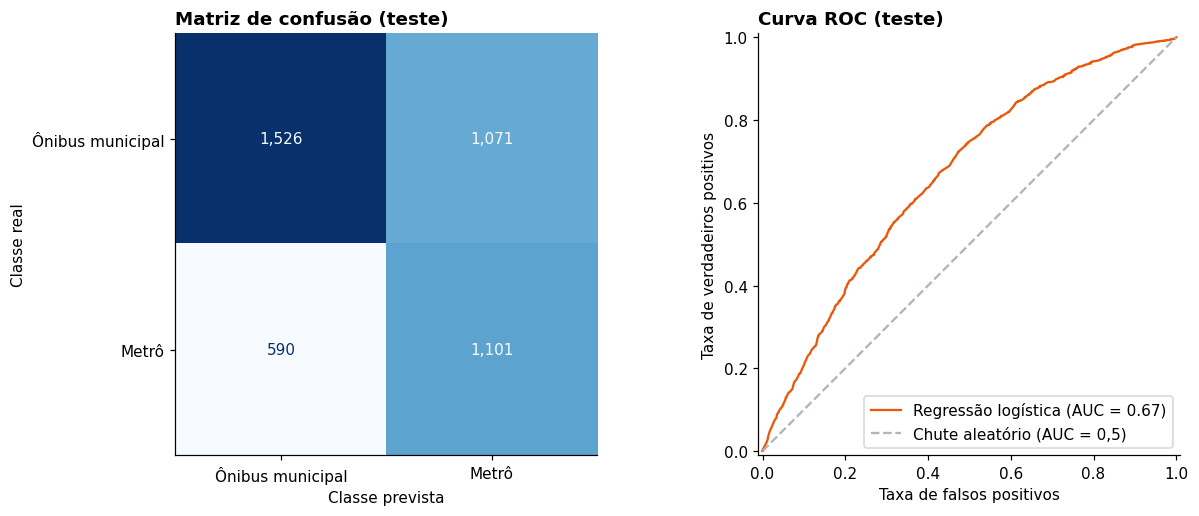

In [10]:
fig, (eixo1, eixo2) = plt.subplots(1, 2, figsize=(12, 4.8))
ConfusionMatrixDisplay(confusion_matrix(y_teste, previsto),
                       display_labels=["Ônibus municipal", "Metrô"]).plot(ax=eixo1, cmap="Blues", colorbar=False, values_format=",")
eixo1.set_title("Matriz de confusão (teste)", loc="left", fontweight="bold")
eixo1.set_xlabel("Classe prevista")
eixo1.set_ylabel("Classe real")

RocCurveDisplay.from_predictions(y_teste, probabilidade, ax=eixo2, name="Regressão logística", color="#e8590c")
eixo2.plot([0, 1], [0, 1], "--", color="#adb5bd", label="Chute aleatório (AUC = 0,5)")
eixo2.set_title("Curva ROC (teste)", loc="left", fontweight="bold")
eixo2.set_xlabel("Taxa de falsos positivos")
eixo2.set_ylabel("Taxa de verdadeiros positivos")
eixo2.legend(loc="lower right")
fig.tight_layout()
fig.savefig("figuras/2_matriz_confusao_e_roc.png", bbox_inches="tight")
plt.show()

**Como ler esses números:**

- A **acurácia de 61,3%** parece pouco acima da referência que chuta sempre "ônibus" (60,6%). Mas essa referência nunca acerta um usuário de metrô: a **acurácia balanceada** (média da revocação das duas classes) mostra a diferença real, **61,9% contra 50%**.
- O modelo encontra **65,1% dos usuários de metrô** (revocação), ao custo de classificar como metrô **41% dos usuários de ônibus** (1.071 de 2.597). Por isso a **precisão do metrô é 50,7%**: metade das pessoas que o modelo aponta como "metrô" é de fato usuária de metrô.
- O **AUC de 0,667** indica capacidade de separação **fraca a moderada**: sorteando um usuário de metrô e um de ônibus, o modelo dá a maior probabilidade de metrô ao usuário certo em 67% das vezes (50% seria chute).
- A **validação cruzada** em 5 partes deu acurácia de 0,613 ± 0,007 e AUC de 0,668 ± 0,006, iguais às do teste. O resultado é estável e o modelo **não está decorando** o conjunto de treino.
- Conclusão parcial: o perfil **ajuda** a distinguir os dois públicos, mas **não basta** para acertar a maioria dos casos individuais.

## 5. Análise multivariada: o peso de cada característica

Os coeficientes abaixo vêm da mesma regressão logística, ajustada com o `statsmodels` no conjunto de treino para obter os **testes de hipótese de cada coeficiente** (teste de Wald):

- $H_0$: $\beta_j = 0$ (a característica não muda a chance de usar o metrô, mantidas as outras iguais).
- $H_1$: $\beta_j \neq 0$.

A **razão de chances** $e^{\beta_j}$ compara com a categoria de referência: 2,0 significa o dobro da chance de usar metrô em vez de ônibus; 0,5 significa metade. Aqui o modelo é ajustado **sem** o balanceamento de classes, porque o objetivo é interpretar os coeficientes, não classificar.

In [11]:
codificador = modelo.named_steps["codificar"]
X_treino_cod = pd.DataFrame(codificador.transform(X_treino).toarray(),
                            columns=[nome.replace("perfil__", "") for nome in codificador.get_feature_names_out()])
logit = sm.Logit(y_treino.values, sm.add_constant(X_treino_cod)).fit(disp=False)

coeficientes = pd.DataFrame({
    "coeficiente (β)": logit.params,
    "razão de chances": np.exp(logit.params),
    "IC 95% inferior": np.exp(logit.conf_int()[0]),
    "IC 95% superior": np.exp(logit.conf_int()[1]),
    "p-valor": logit.pvalues,
}).drop(index="const")
coeficientes["significativo (5%)"] = np.where(coeficientes["p-valor"] < 0.05, "sim", "não")
print(f"Pseudo R² de McFadden: {logit.prsquared:.3f}")
print(f"Teste da razão de verossimilhança (todos os β = 0): p-valor = {logit.llr_pvalue:.2e}")
coeficientes.sort_values("razão de chances").style.format({
    "coeficiente (β)": "{:+.3f}", "razão de chances": "{:.2f}", "IC 95% inferior": "{:.2f}",
    "IC 95% superior": "{:.2f}", "p-valor": "{:.3g}"})

Pseudo R² de McFadden: 0.064
Teste da razão de verossimilhança (todos os β = 0): p-valor = 2.51e-171


,coeficiente (β),razão de chances,IC 95% inferior,IC 95% superior,p-valor,significativo (5%)
faixa_renda_1/2 a 1 SM,-0.023,0.98,0.81,1.18,0.808,não
situacao_Sem trabalho/do lar,+0.064,1.07,0.84,1.35,0.589,não
escolaridade_2 Fund. I completo,+0.068,1.07,0.83,1.38,0.593,não
escolaridade_3 Fund. II completo,+0.116,1.12,0.89,1.42,0.33,não
carros_1,+0.118,1.13,1.03,1.23,0.0119,sim
carros_2 ou mais,+0.185,1.20,1.03,1.41,0.0198,sim
faixa_renda_1 a 2 SM,+0.208,1.23,1.02,1.48,0.0279,sim
sexo_Masculino,+0.221,1.25,1.15,1.36,3.59e-07,sim
situacao_Trabalha,+0.263,1.30,1.08,1.57,0.00641,sim
situacao_Estudante,+0.489,1.63,1.27,2.10,0.000158,sim


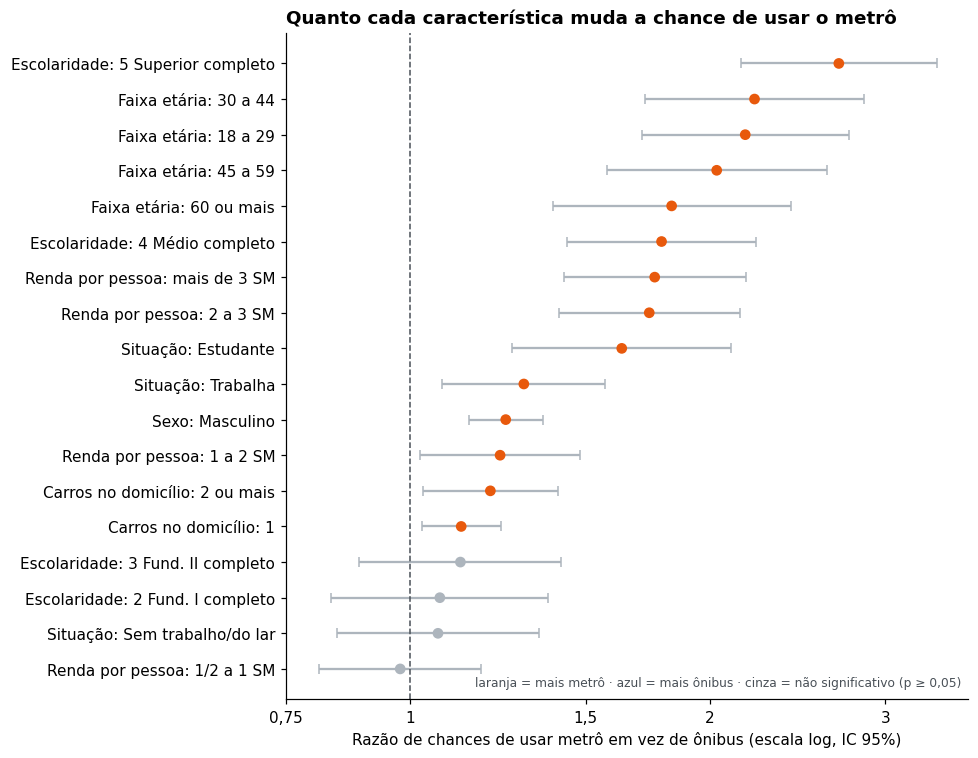

In [12]:
def nome_legivel(coluna):
    for variavel in PERFIL:
        if coluna.startswith(variavel + "_"):
            return f"{NOMES[variavel].split(' (')[0]}: {coluna[len(variavel) + 1:]}"
    return coluna

ordenado = coeficientes.sort_values("razão de chances")
cores = ["#adb5bd" if p >= 0.05 else ("#e8590c" if razao > 1 else "#1c7ed6")
         for razao, p in zip(ordenado["razão de chances"], ordenado["p-valor"])]
fig, eixo = plt.subplots(figsize=(9, 7))
eixo.errorbar(ordenado["razão de chances"], range(len(ordenado)),
              xerr=[ordenado["razão de chances"] - ordenado["IC 95% inferior"],
                    ordenado["IC 95% superior"] - ordenado["razão de chances"]],
              fmt="none", ecolor="#adb5bd", capsize=3)
eixo.scatter(ordenado["razão de chances"], range(len(ordenado)), color=cores, zorder=3)
eixo.axvline(1, color="#495057", linestyle="--", linewidth=1)
eixo.set_xscale("log")
eixo.set_xticks([0.75, 1, 1.5, 2, 3])
eixo.set_xticklabels(["0,75", "1", "1,5", "2", "3"])
eixo.minorticks_off()
eixo.set_yticks(range(len(ordenado)))
eixo.set_yticklabels([nome_legivel(nome) for nome in ordenado.index])
eixo.set_xlabel("Razão de chances de usar metrô em vez de ônibus (escala log, IC 95%)")
eixo.set_title("Quanto cada característica muda a chance de usar o metrô", loc="left", fontweight="bold")
eixo.text(0.99, 0.02, "laranja = mais metrô · azul = mais ônibus · cinza = não significativo (p ≥ 0,05)", transform=eixo.transAxes,
          ha="right", fontsize=8, color="#495057")
fig.tight_layout()
fig.savefig("figuras/3_razoes_de_chances.png", bbox_inches="tight")
plt.show()

**O que os coeficientes dizem** (sempre comparando com a referência e mantendo as outras características iguais):

- **Escolaridade é o fator mais forte.** Quem tem **superior completo tem 2,69 vezes a chance** de usar metrô em vez de ônibus de quem não completou o fundamental I; com médio completo, 1,79 vez. Os níveis intermediários do fundamental **não diferem** da referência (p > 0,3).
- **Idade:** todos os adultos têm cerca de **2 vezes** a chance dos menores de 18 anos (de 1,83 a 2,22). Adolescentes dependem mais do ônibus, que chega perto da escola e do bairro.
- **Renda:** a partir de **2 salários mínimos por pessoa**, a chance de usar metrô é **1,74 vez** maior; entre meio e um salário, não há diferença significativa.
- **Situação:** estudantes (1,63) e quem trabalha (1,30) usam mais o metrô que aposentados, provavelmente porque fazem viagens longas até o centro.
- **Sexo:** homens têm **1,25 vez** a chance das mulheres. O efeito é pequeno, mas tem o intervalo de confiança mais estreito de todos.
- **Carros:** ter carro **aumenta um pouco** a chance de usar metrô (1,13 a 1,20). Isso parece contraditório, mas faz sentido: entre quem **escolheu o transporte público**, quem tem carro costuma morar em regiões mais centrais e mais ricas, onde há metrô.
- O **pseudo R² de 0,064** confirma o que as métricas mostraram: as características são significativas (teste da razão de verossimilhança com p = 2,5 × 10⁻¹⁷¹), mas explicam uma parte pequena da escolha.

### 5.1 Perfis típicos

Probabilidade estimada de usar o metrô para alguns perfis, usando o modelo da seção 4 (balanceado). Isso mostra o modelo funcionando como **classificador de perfil**.

In [13]:
perfis = pd.DataFrame([
    ["Feminino", "30 a 44", "2 Fund. I completo", "1/2 a 1 SM", "Trabalha", "0"],
    ["Masculino", "18 a 29", "4 Médio completo", "1 a 2 SM", "Trabalha", "0"],
    ["Feminino", "18 a 29", "5 Superior completo", "mais de 3 SM", "Trabalha", "1"],
    ["Masculino", "60 ou mais", "1 Fund. I incompleto", "até 1/2 SM", "Aposentado", "0"],
    ["Feminino", "até 17", "3 Fund. II completo", "1/2 a 1 SM", "Estudante", "1"],
], columns=PERFIL)
perfis["P(metrô)"] = modelo.predict_proba(perfis)[:, 1]
perfis["classe prevista"] = np.where(perfis["P(metrô)"] >= 0.5, "Metrô", "Ônibus municipal")
perfis.style.format({"P(metrô)": "{:.0%}"}).hide(axis="index")

sexo,faixa_etaria,escolaridade,faixa_renda,situacao,carros,P(metrô),classe prevista
Feminino,30 a 44,2 Fund. I completo,1/2 a 1 SM,Trabalha,0,30%,Ônibus municipal
Masculino,18 a 29,4 Médio completo,1 a 2 SM,Trabalha,0,53%,Metrô
Feminino,18 a 29,5 Superior completo,mais de 3 SM,Trabalha,1,69%,Metrô
Masculino,60 ou mais,1 Fund. I incompleto,até 1/2 SM,Aposentado,0,25%,Ônibus municipal
Feminino,até 17,3 Fund. II completo,1/2 a 1 SM,Estudante,1,23%,Ônibus municipal


## 6. Análise complementar: perfil ou acesso?

O perfil explica só parte da escolha. Uma hipótese é que **onde a pessoa mora** pesa muito: a rede de metrô se concentra no centro expandido. Para testar, a distância em linha reta da casa até o centro (Sé), calculada pelas coordenadas do domicílio na própria pesquisa, foi acrescentada ao modelo. Ela é só um indicador aproximado de acesso, porque a pesquisa não traz a distância até a estação mais próxima.

In [14]:
binaria["faixa_distancia"] = pd.cut(binaria["dist_centro_km"], [0, 5, 10, 15, 20, 100],
                                    labels=["até 5 km", "5 a 10 km", "10 a 15 km", "15 a 20 km", "mais de 20 km"])
por_distancia = binaria.groupby("faixa_distancia", observed=True).agg(
    pessoas=("servico", "size"), usa_metro=("servico", lambda s: (s == "Metrô").mean() * 100))
print("Uso do metrô (entre ônibus e metrô) conforme a distância da casa até o centro:")
print(por_distancia.round(1).rename(columns={"usa_metro": "% metrô"}))

def modelo_com_distancia():
    codificador = ColumnTransformer([
        ("perfil", OneHotEncoder(categories=CATEGORIAS, drop="first"), PERFIL),
        ("distancia", StandardScaler(), ["dist_centro_km"])])
    return Pipeline([("codificar", codificador),
                     ("logistica", LogisticRegression(max_iter=2000, class_weight="balanced"))])

comparacao = {}
for nome, construtor, colunas in [("Só perfil", novo_modelo, PERFIL),
                                  ("Perfil + distância ao centro", modelo_com_distancia, PERFIL + ["dist_centro_km"])]:
    comparacao[nome] = {
        "AUC ROC": cross_val_score(construtor(), binaria[colunas], y, cv=validacao, scoring="roc_auc").mean(),
        "acurácia balanceada": cross_val_score(construtor(), binaria[colunas], y, cv=validacao, scoring="balanced_accuracy").mean(),
    }
print()
print("Validação cruzada (5 partes):")
pd.DataFrame(comparacao).T

Uso do metrô (entre ônibus e metrô) conforme a distância da casa até o centro:
                 pessoas  % metrô
faixa_distancia                  
até 5 km            3224   53.300
5 a 10 km           3749   45.900
10 a 15 km          3098   29.900
15 a 20 km          2240   30.800
mais de 20 km       1981   29.600



Validação cruzada (5 partes):


,AUC ROC,acurácia balanceada
Só perfil,0.668,0.619
Perfil + distância ao centro,0.676,0.628


**Resultado:** onde a pessoa mora pesa tanto quanto o perfil. Entre quem mora a **até 5 km do centro, 53% usam metrô**; a partir de **10 km, só cerca de 30%**. Mesmo com um indicador tão simples (distância em linha reta até a Sé), o modelo melhora de AUC 0,668 para **0,676** e de acurácia balanceada 0,619 para **0,628**.

O ganho é pequeno porque a distância até o centro é uma aproximação grosseira do acesso. Ela não sabe, por exemplo, que Itaquera fica a mais de 15 km da Sé e tem estação de metrô. Com a **distância até a estação mais próxima**, que pode ser calculada com as coordenadas das estações do Metrô, a melhora tende a ser bem maior. Isso indica que **a escolha entre ônibus e metrô depende mais de acesso do que de perfil**: muita gente usa o ônibus porque é o único serviço que passa perto de casa.

## 7. Extensão: três serviços (ônibus, metrô e trem)

O mesmo modelo, agora com três classes (regressão logística multinomial), incluindo o trem da CPTM.

                  precision    recall  f1-score   support

Ônibus municipal      0.728     0.346     0.469      2597
           Metrô      0.502     0.492     0.497      1691
            Trem      0.066     0.530     0.117       198

        accuracy                          0.409      4486
       macro avg      0.432     0.456     0.361      4486
    weighted avg      0.613     0.409     0.464      4486



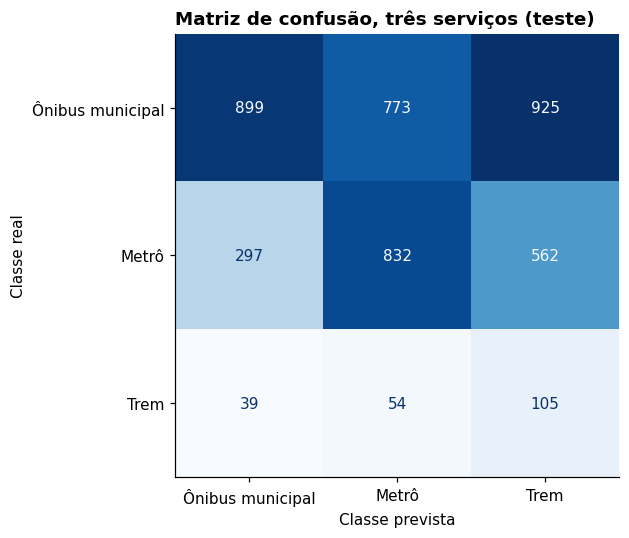

In [15]:
X3 = dados[PERFIL]
y3 = dados["servico"]
X3_treino, X3_teste, y3_treino, y3_teste = train_test_split(
    X3, y3, test_size=0.30, stratify=y3, random_state=SEMENTE)
modelo3 = novo_modelo(multiclasse=True).fit(X3_treino, y3_treino)
previsto3 = modelo3.predict(X3_teste)

print(classification_report(y3_teste, previsto3, labels=ORDEM_SERVICOS, digits=3))
fig, eixo = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(confusion_matrix(y3_teste, previsto3, labels=ORDEM_SERVICOS),
                       display_labels=ORDEM_SERVICOS).plot(ax=eixo, cmap="Blues", colorbar=False, values_format=",")
eixo.set_title("Matriz de confusão, três serviços (teste)", loc="left", fontweight="bold")
eixo.set_xlabel("Classe prevista")
eixo.set_ylabel("Classe real")
fig.tight_layout()
fig.savefig("figuras/4_matriz_confusao_tres_servicos.png", bbox_inches="tight")
plt.show()

Com três classes, o modelo fica bem pior: **acurácia de 40,9%** e F1 médio de 0,361. O problema é o **trem**: só 4,4% das pessoas o usam, e o balanceamento faz o modelo apostar em trem com frequência (revocação de 53%), mas **acerta só 6,6% das vezes que aposta**. O perfil de quem usa trem é muito parecido com o de quem usa ônibus; o que define o uso do trem é **morar perto de uma linha da CPTM**, uma informação de localização que o perfil não carrega. Por isso o modelo principal compara só ônibus e metrô.

## 8. Conclusões

**Descobertas:**

1. Os usuários de ônibus municipal e de metrô em São Paulo têm **perfis diferentes**, com associação estatisticamente significativa nas seis características testadas (qui-quadrado, p < 0,05).
2. O usuário típico do **ônibus** tem **menos escolaridade, menor renda, é mais jovem (menor de 18 anos) ou mais velho, e é mais frequentemente mulher**. O do **metrô** tem **ensino médio ou superior completo, renda acima de 2 salários mínimos por pessoa e trabalha ou estuda**.
3. A regressão logística classifica os dois públicos com **AUC de 0,67 e acurácia balanceada de 62%**, resultados estáveis na validação cruzada. O perfil explica **parte** da escolha; **onde a pessoa mora** explica outra parte importante, e o trem praticamente só é explicado pela localização.

**Aplicações práticas:**

- **Linguagem e canais por serviço:** como o público do ônibus tem menos escolaridade e renda, as informações nos pontos de ônibus devem usar linguagem simples, áudio e atendimento presencial, e não depender só de aplicativo. É exatamente o público do **Ponto Vivo**, o assistente no ponto de ônibus com QR code.
- **Direitos que quem mais precisa não conhece:** o público do ônibus é o que mais tem direito a gratuidades e meia tarifa (idosos, estudantes, baixa renda). O assistente pode priorizar essas orientações nos pontos das regiões com perfil de menor renda.
- **Planejamento:** os resultados reforçam que ampliar o acesso ao metrô em regiões periféricas atende um público de menor renda, que hoje depende do ônibus.

**Limitações e próximos passos:** os dados são de 2017; o modelo usa só o perfil (e, na análise complementar, a distância até o centro); a OD não informa a distância até a estação mais próxima. O próximo passo é calcular essa distância com as coordenadas das estações e testar modelos não lineares (como árvores de decisão) para comparar com a regressão logística.